# Thông tin đồ án giữa kì
- Họ tên: Nguyễn Tuấn Khải
- MSSV: 51.01.104.125
- Mã HP: 2611COMP180401 - Lập trình Python
- GVHD: ThS. Lương Trần Hy Hiến


# Phân tích dữ liệu bằng Python và xây dựng mô hình

**Mục tiêu:** xây dựng một quy trình DA có thể chạy từ đầu đến cuối bằng Pandas, NumPy, Matplotlib và Seaborn; sau đó có thể mở rộng thêm phân tích hoặc mô hình Regression.

**Nguồn:** [Melbourne Housing Snapshot — Kaggle](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot). Trang dữ liệu mô tả đây là snapshot của dữ liệu do Tony Pino tạo, thu thập bằng phương pháp cào dữ liệu web (web scraping) từ các tin đăng công khai qua https://www.domain.com.au; notebook này không tự cào dữ liệu mà đọc tệp CSV đã tải từ Kaggle. Giấy phép được ghi trên Kaggle là **CC BY-NC-SA 4.0**; cần giữ ghi công và tuân thủ điều kiện giấy phép khi chia sẻ hoặc biến đổi dữ liệu.

**Phạm vi:** bộ dữ liệu lịch sử ở Melbourne, Australia, không đại diện cho giá nhà hiện tại hoặc thị trường Việt Nam.

**Luồng thực hiện:** Dataset → Data Cleaning → Analysis → Visualization

## 0. Chuẩn bị môi trường

Cài thư viện một lần trong Terminal của VS Code (nếu chưa có):

```powershell
python -m pip install pandas numpy matplotlib seaborn jupyter
```

Đặt `melb_data.csv` ở thư mục `data/` cạnh notebook theo cấu trúc dự án, hoặc điều chỉnh `DATA_PATH` ở cell bên dưới.

In [156]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "melb_data.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Thư mục làm việc:", PROJECT_DIR)
print("Đường dẫn dataset:", DATA_PATH)

Thư mục làm việc: /content
Đường dẫn dataset: /content/data/melb_data.csv


## 1. Đọc dữ liệu bằng Pandas

Không chỉnh sửa dữ liệu gốc trực tiếp. `df_raw` được giữ làm bản tham chiếu để đối chiếu trước/sau làm sạch.

In [157]:
if not DATA_PATH.exists():
    # Cho phép đặt CSV ngay cạnh notebook nếu không dùng thư mục data/
    alternative_path = PROJECT_DIR / "melb_data.csv"
    if alternative_path.exists():
        DATA_PATH = alternative_path
    else:
        raise FileNotFoundError(
            f"Không tìm thấy {DATA_PATH}. Hãy đặt melb_data.csv trong data/ "
            "hoặc cùng thư mục với notebook, rồi chạy lại cell này."
        )

# Hiển thị 5 dòng đầu tiên của dataset
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print(f"Dataset có {df_raw.shape[0]:,} dòng và {df_raw.shape[1]} cột.")
display(df_raw.head())

Dataset có 13,580 dòng và 21 cột.


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


## 2. Tổng quan và mô tả thuộc tính

Dataset có các biến về khu vực (`Suburb`, `Regionname`, `CouncilArea`), đặc điểm bất động sản (`Rooms`, `Type`, `Bathroom`, `Car`, `Landsize`, `BuildingArea`, `YearBuilt`) và giá (`Price`).

In [158]:
# Hiển thị thông tin cơ bản về dataset
print("Kích thước:", df_raw.shape)
print("Số dòng trùng hoàn toàn:", df_raw.duplicated().sum())
print("Số thuộc tính:", df_raw.shape[1])

# Từ điển data
data_dictionary = pd.DataFrame([
    ("Suburb", "Khu vực nhỏ/suburb"),
    ("Address", "Địa chỉ bất động sản"),
    ("Rooms", "Số phòng"),
    ("Type", "Loại bất động sản: h, u, t"),
    ("Price", "Giá bán, AUD; biến quan tâm chính"),
    ("Method", "Mã phương thức/kết quả bán"),
    ("SellerG", "Đơn vị/môi giới bán"),
    ("Date", "Ngày giao dịch/bán theo dataset"),
    ("Distance", "Khoảng cách đến CBD, km"),
    ("Postcode", "Mã bưu chính"),
    ("Bedroom2", "Số phòng ngủ theo nguồn dữ liệu"),
    ("Bathroom", "Số phòng tắm"),
    ("Car", "Số chỗ đậu xe"),
    ("Landsize", "Diện tích đất"),
    ("BuildingArea", "Diện tích xây dựng"),
    ("YearBuilt", "Năm xây dựng"),
    ("CouncilArea", "Khu vực chính quyền địa phương"),
    ("Lattitude", "Vĩ độ; tên cột theo file gốc"),
    ("Longtitude", "Kinh độ; tên cột theo file gốc"),
    ("Regionname", "Vùng địa lý lớn"),
    ("Propertycount", "Số bất động sản tại suburb"),
], columns=["Column", "Mô tả"])
display(data_dictionary)

Kích thước: (13580, 21)
Số dòng trùng hoàn toàn: 0
Số thuộc tính: 21


,Column,Mô tả
0,Suburb,Khu vực nhỏ/suburb
1,Address,Địa chỉ bất động sản
2,Rooms,Số phòng
3,Type,"Loại bất động sản: h, u, t"
4,Price,"Giá bán, AUD; biến quan tâm chính"
5,Method,Mã phương thức/kết quả bán
6,SellerG,Đơn vị/môi giới bán
7,Date,Ngày giao dịch/bán theo dataset
8,Distance,"Khoảng cách đến CBD, km"
9,Postcode,Mã bưu chính


## 3. Kiểm tra dữ liệu

Kiểm tra kiểu dữ liệu bằng `dtypes`, `info()` và chuyển `Date` sang datetime ở bước làm sạch. Các cột mã như `Postcode` có thể được cân nhắc xem là biến phân loại trong phân tích, dù file gốc biểu diễn chúng dưới dạng số.

In [159]:
# Đọc data
dtype_report = pd.DataFrame({
    "Kiểu data": df_raw.dtypes.astype(str),
    "Số lượng không null": df_raw.notna().sum(),
    "Số giá trị duy nhất": df_raw.nunique(dropna=True),
})
display(dtype_report)

# Giá cao nhất/thấp nhất
print(f"Giá cao nhất: ${df_raw['Price'].max():,}")
print(f"Giá thấp nhất: ${df_raw['Price'].min():,}")

# Giá trung vị/trung bình
print(f"Giá trung vị: ${df_raw['Price'].median():,}")
print(f"Giá trung bình: ${df_raw['Price'].mean():,.2f}")

#IQR (Tứ phân vị) Price
q1 = df_raw['Price'].quantile(0.25)
q3 = df_raw['Price'].quantile(0.75)
iqr = q3 - q1
print (f"Q1: {q1}, Q3: {q3}, IQR: {iqr}")

#Cơ cấu nhà theo loại
type_counts = df_raw['Type'].value_counts()
print("Cơ cấu nhà theo loại:")
for type_name, count in type_counts.items():
    print(f"  {type_name}: {count} - {count / len(df_raw) * 100:.2f}%")

# Cơ cấu % nhà theo vùng
print("Cơ cấu nhà theo vùng:")
region_counts = df_raw['Regionname'].value_counts()
for region_name, count in region_counts.items():
    print(f"  {region_name}: {count} - {count / len(df_raw) * 100:.2f}%")

# Số cột các loại giá trị
print("Số cột các loại giá trị:")
for dtype, count in df_raw.dtypes.value_counts().items():
    print(f"  {dtype}: {count}")

#Tổng số dòng trùng, dòng có giá trị null và dòng có giá Price không hợp lệ
duplicate_rows = df_raw.duplicated().sum()
null_rows = df_raw.isnull().any(axis=1).sum()
invalid_price_rows = df_raw[df_raw['Price'].isnull() | (df_raw['Price'] <= 0)].shape[0]
print(f"Tổng số dòng trùng: {duplicate_rows}")
print(f"Tổng số dòng có giá trị null: {null_rows}")
print(f"Tổng số dòng có giá Price không hợp lệ: {invalid_price_rows}")

,Kiểu data,Số lượng không null,Số giá trị duy nhất
Suburb,object,13580,314
Address,object,13580,13378
Rooms,int64,13580,9
Type,object,13580,3
Price,float64,13580,2204
Method,object,13580,5
SellerG,object,13580,268
Date,object,13580,58
Distance,float64,13580,202
Postcode,float64,13580,198


Giá cao nhất: $9,000,000.0
Giá thấp nhất: $85,000.0
Giá trung vị: $903,000.0
Giá trung bình: $1,075,684.08
Q1: 650000.0, Q3: 1330000.0, IQR: 680000.0
Cơ cấu nhà theo loại:
  h: 9449 - 69.58%
  u: 3017 - 22.22%
  t: 1114 - 8.20%
Cơ cấu nhà theo vùng:
  Southern Metropolitan: 4695 - 34.57%
  Northern Metropolitan: 3890 - 28.65%
  Western Metropolitan: 2948 - 21.71%
  Eastern Metropolitan: 1471 - 10.83%
  South-Eastern Metropolitan: 450 - 3.31%
  Eastern Victoria: 53 - 0.39%
  Northern Victoria: 41 - 0.30%
  Western Victoria: 32 - 0.24%
Số cột các loại giá trị:
  float64: 12
  object: 8
  int64: 1
Tổng số dòng trùng: 0
Tổng số dòng có giá trị null: 7384
Tổng số dòng có giá Price không hợp lệ: 0


## 4. Phát hiện dữ liệu thiếu, trùng và giá trị đáng ngờ

In [160]:
# Báo cáo thiếu dữ liệu
missing_report = pd.DataFrame({
    "Số ô thiếu": df_raw.isna().sum(),
    "Tỷ lệ thiếu (%)": (df_raw.isna().mean() * 100).round(2),
    "Giá trị duy nhất": df_raw.nunique(dropna=True),
}).sort_values("Tỷ lệ thiếu (%)", ascending=False)
print("Báo cáo thiếu dữ liệu:")
display(missing_report)
print("Số dòng trùng hoàn toàn:", int(df_raw.duplicated().sum()))

# Kiểm tra giá trị bất thường
invalid_report = pd.Series({
    "Price ≤  0": (df_raw["Price"] <=  0).sum(),
    "Rooms ≤  0": (df_raw["Rooms"] <=  0).sum(),
    "Distance < 0": (df_raw["Distance"] < 0).sum(),
    "Landsize < 0": (df_raw["Landsize"] < 0).sum(),
    "BuildingArea ≤  0": (df_raw["BuildingArea"] <=  0).sum(),
    "YearBuilt < 1700": (df_raw["YearBuilt"] < 1700).sum(),
    "Landsize = 0": (df_raw["Landsize"] == 0).sum(),
    "Landsize > 10000": (df_raw["Landsize"] > 10_000).sum(),
    "BuildingArea > 1000": (df_raw["BuildingArea"] > 1_000).sum(),
    "Bathroom = 0": (df_raw["Bathroom"] == 0).sum(),
    "YearBuilt ≥ 2017": (df_raw["YearBuilt"] >= 2017).sum(),
    "Distance = 0": (df_raw["Distance"] == 0).sum(),
    "Rooms ≥ 7": (df_raw["Rooms"] >= 7).sum(),
    "Longtitude & Lattitude out of range": ((df_raw["Longtitude"] < 140) | (df_raw["Longtitude"] > 150) | (df_raw["Lattitude"] < -40) | (df_raw["Lattitude"] > -30)).sum()
}, name="Số bản ghi")
print("Các quy tắc kiểm tra tính hợp lệ:")
display(invalid_report.to_frame())





Báo cáo thiếu dữ liệu:


,Số ô thiếu,Tỷ lệ thiếu (%),Giá trị duy nhất
BuildingArea,6450,47.50,602
YearBuilt,5375,39.58,144
CouncilArea,1369,10.08,33
Car,62,0.46,11
Suburb,0,0.00,314
Price,0,0.00,2204
Type,0,0.00,3
Rooms,0,0.00,9
Address,0,0.00,13378
Distance,0,0.00,202


Số dòng trùng hoàn toàn: 0
Các quy tắc kiểm tra tính hợp lệ:


,Số bản ghi
Price ≤ 0,0
Rooms ≤ 0,0
Distance < 0,0
Landsize < 0,0
BuildingArea ≤ 0,17
YearBuilt < 1700,1
Landsize = 0,1939
Landsize > 10000,26
BuildingArea > 1000,8
Bathroom = 0,34


## 5. Làm sạch dữ liệu

1. Sao chép dữ liệu gốc và loại dòng trùng hoàn toàn.
2. Chuyển `Date` sang datetime với `dayfirst=True`.
3. Ép các cột số về kiểu số; giá trị không chuyển được thành số sẽ thành thiếu.
4. Chuyển các giá trị rõ ràng không hợp lý thành `NaN`: `Price ≤  0`, `Rooms ≤  0`, `Distance < 0`, `Landsize < 0`, `BuildingArea ≤  0`, `YearBuilt < 1700` và tọa độ ngoài vùng kiểm tra rộng của Melbourne.
5. Loại ngoại lai: đặt `Landsize > 10.000` m², `BuildingArea > 1.000` m² và `Bathroom == 0` thành `NaN`. Giao dịch và giá được giữ nguyên, chỉ bỏ giá trị đáng ngờ. Giữ `Landsize == 0` vì nghĩa là không có đất riêng (chủ yếu là căn hộ), không phải lỗi.
6. Loại dòng không có giá bán hợp lệ vì các phân tích trọng tâm so sánh giá.
7. Điền thiếu `CouncilArea` thành `Unknown`; không tự điền trung vị cho `BuildingArea` và `YearBuilt` vì tỷ lệ thiếu cao và phép điền có thể làm méo thống kê mô tả.
8. Thêm `SaleYear`/`SaleMonth` phục vụ phân tích thời gian và cờ chỉ ra giá trị vốn đã thiếu trong một số cột.

Giá bán cao không bị coi là ngoại lai để loại bỏ: đó là các giao dịch có thể có thật, nên chỉ được đánh dấu bằng IQR ở bước 4.

Các ngưỡng hợp lệ là quy tắc phân tích cần được mô tả trong báo cáo, không phải chân lý tuyệt đối của dữ liệu bất động sản.

In [161]:
# Hàm làm sạch dữ liệu
def clean_data(df_input: pd.DataFrame) -> pd.DataFrame:
    data = df_input.copy().drop_duplicates().copy()

# Xử lý cột ngày tháng
    if "Date" in data.columns:
        data["Date"] = pd.to_datetime(data["Date"], dayfirst=True, errors="coerce")

# Đảm bảo các cột số là kiểu số, chuyển đổi các giá trị không hợp lệ thành NaN
    numeric_cols = [
        "Rooms", "Price", "Distance", "Postcode", "Bedroom2", "Bathroom",
        "Car", "Landsize", "BuildingArea", "YearBuilt", "Lattitude",
        "Longtitude", "Propertycount"
    ]
    for col in numeric_cols:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

# Giữ nguyên thông tin về các giá trị bị thiếu trước khi loại bỏ các giá trị không hợp lý
    for col in ["Car", "BuildingArea", "YearBuilt", "CouncilArea"]:
        if col in data.columns:
            data[f"{col}_was_missing"] = data[col].isna().astype("int8")

# Loại bỏ các giá trị không hợp lý theo quy tắc đã xác định
    data.loc[data["Price"] <=  0, "Price"] = np.nan
    data.loc[data["Rooms"] <=  0, "Rooms"] = np.nan
    data.loc[data["Distance"] < 0, "Distance"] = np.nan
    data.loc[data["Landsize"] < 0, "Landsize"] = np.nan
    data.loc[data["BuildingArea"] <=  0, "BuildingArea"] = np.nan
    data.loc[data["YearBuilt"] < 1700, "YearBuilt"] = np.nan
    data.loc[data["Landsize"] > 10_000, "Landsize"] = np.nan
    data.loc[data["BuildingArea"] > 1_000, "BuildingArea"] = np.nan
    data.loc[data["Bathroom"] == 0, "Bathroom"] = np.nan
    data.loc[~data["Lattitude"].between(-39.5, -36.0), "Lattitude"] = np.nan
    data.loc[~data["Longtitude"].between(142.0, 147.0), "Longtitude"] = np.nan

# Loại bỏ các dòng có giá trị null trong cột Price và điền giá trị "Unknown" cho cột CouncilArea nếu bị thiếu
# Giữ Price vì đây là biến mục tiêu
    data = data.dropna(subset=["Price"])
    data["CouncilArea"] = data["CouncilArea"].fillna("Unknown")

# Tách cột ngày tháng thành các cột riêng biệt cho năm và tháng
# Lí do tách: để phân tích xu hướng giá theo thời gian xác định
    data["SaleYear"] = data["Date"].dt.year
    data["SaleMonth"] = data["Date"].dt.month
    return data.reset_index(drop=True)

#In thông tin
df_clean = clean_data(df_raw)
print("Kích thước ban đầu:", df_raw.shape)
print("Kích thước sau làm sạch:", df_clean.shape)
print("Dòng trùng còn lại:", df_clean.duplicated().sum())
print("Ngày không parse được:", df_clean["Date"].isna().sum())
display(df_clean.head())

Kích thước ban đầu: (13580, 21)
Kích thước sau làm sạch: (13580, 27)
Dòng trùng còn lại: 0
Ngày không parse được: 0


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,Car_was_missing,BuildingArea_was_missing,YearBuilt_was_missing,CouncilArea_was_missing,SaleYear,SaleMonth
0,Abbotsford,85 Turner St,2.0,h,1480000.0,S,Biggin,2016-12-03,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0,0,1,1,0,2016,12
1,Abbotsford,25 Bloomburg St,2.0,h,1035000.0,S,Biggin,2016-02-04,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0,0,0,0,0,2016,2
2,Abbotsford,5 Charles St,3.0,h,1465000.0,SP,Biggin,2017-03-04,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0,0,0,0,0,2017,3
3,Abbotsford,40 Federation La,3.0,h,850000.0,PI,Biggin,2017-03-04,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0,0,1,1,0,2017,3
4,Abbotsford,55a Park St,4.0,h,1600000.0,VB,Nelson,2016-06-04,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0,0,0,0,0,2016,6


### 5.1. Đối chiếu dữ liệu sau làm sạch

Đánh giá xem dữ liệu còn thiếu ở đâu. Giữ `NaN` trong các biến có tỷ lệ thiếu lớn là một quyết định có chủ đích; các phân tích liên quan đến biến đó sẽ dùng các dòng có dữ liệu quan sát được và phải nêu rõ khi diễn giải.

In [162]:
#Report data sau làm sạch
clean_missing_report = pd.DataFrame({
    "số lượng missing": df_clean.isna().sum(),
    "% missing": (df_clean.isna().mean() * 100).round(2),
}).sort_values("% missing", ascending=False)
display(clean_missing_report.head(12))

# Lưu bản sạch để có thể dùng lại ở các phần sau.
clean_path = OUTPUT_DIR / "melb_data_clean.csv"
df_clean.to_csv(clean_path, index=False, encoding="utf-8-sig")
print("Đã lưu:", clean_path)

,số lượng missing,% missing
BuildingArea,6475,47.68
YearBuilt,5376,39.59
Car,62,0.46
Bathroom,34,0.25
Landsize,26,0.19
Method,0,0.00
Price,0,0.00
Type,0,0.00
Suburb,0,0.00
Address,0,0.00


Đã lưu: /content/outputs/melb_data_clean.csv


## 6. Phân tích/thống kê 1 — Thống kê mô tả giá bán

Dùng `describe()` để xem trung bình, trung vị, độ lệch chuẩn, các phân vị và khoảng giá. So sánh mean với median giúp nhận diện phân phối lệch.

In [163]:
price_summary = (
    df_clean["Price"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .to_frame("Price_AUD")
)
price_log = np.log(df_clean["Price"])

display(price_summary)

print(f"Hệ số biến thiên của Price: {df_clean['Price'].std() / df_clean['Price'].mean():.3f}")
print(f"Skewness của Price: {df_clean['Price'].skew():.3f}")
print(f"Skewness của log(Price): {price_log.skew():.3f}")
print(f"Mean: {df_clean['Price'].mean():,.0f} AUD")
print(f"Median: {df_clean['Price'].median():,.0f} AUD")

,Price_AUD
count,1.358000e+04
mean,1.075684e+06
std,6.393107e+05
min,8.500000e+04
1%,3.000000e+05
5%,4.050000e+05
25%,6.500000e+05
50%,9.030000e+05
75%,1.330000e+06
95%,2.290050e+06


Hệ số biến thiên của Price: 0.594
Skewness của Price: 2.240
Skewness của log(Price): 0.181
Mean: 1,075,684 AUD
Median: 903,000 AUD


## 7. Phân tích/thống kê 2 — Giá theo loại bất động sản (`groupby`)

In [164]:
price_by_type = df_clean.groupby("Type")["Price"].agg(
    count="count", mean="mean", median="median", min="min", max="max"
).sort_values("median", ascending=False)
display(price_by_type.style.format({"mean": "{:,.0f}", "median": "{:,.0f}", "min": "{:,.0f}", "max": "{:,.0f}"}))

,count,mean,median,min,max
Type,,,,,
h,9449,"1,242,665","1,080,000","131,000","9,000,000"
t,1114,"933,735","846,750","300,000","3,475,000"
u,3017,"605,127","560,000","85,000","3,625,000"


## 8. Phân tích/thống kê 3 — Giá phân hóa theo vùng địa lý (Regionname)

**Mục tiêu:** Đánh giá mức độ chênh lệch giá bất động sản giữa các vùng địa lý lớn (`Regionname`) tại Melbourne bằng các chỉ số thống kê mô tả (số lượng giao dịch, trung bình `mean`, trung vị `median`).

**Nhận xét từ kết quả:**
* **Phân khúc cao cấp (Top Tier):**
  * **Southern Metropolitan** dẫn đầu toàn thị trường với giá trung vị đạt **1,250,000 AUD** (trung bình 1,372,963 AUD), đồng thời chiếm tỷ trọng giao dịch lớn nhất (4,695 giao dịch ~ 34.57%).
  * **Eastern Metropolitan** xếp thứ hai với giá trung vị **1,010,000 AUD**. Đây là hai khu vực nội thành/gần trung tâm phía Nam và Đông với chất lượng sống cao và hạ tầng đồng bộ.
* **Phân khúc tầm trung (Mid Tier):**
  * **South-Eastern Metropolitan** (850,000 AUD), **Northern Metropolitan** (806,250 AUD) và **Western Metropolitan** (793,000 AUD) có mức giá tiếp cận dễ hơn. Trong đó, vùng phía Bắc và phía Tây đóng vai trò nguồn cung lớn cho thị trường (lần lượt chiếm 28.65% và 21.71% lượng giao dịch).
* **Phân khúc ngoại ô / Tỉnh lẻ (Outer Tier):**
  * Các vùng **Eastern Victoria** (670,000 AUD), **Northern Victoria** (540,000 AUD) và **Western Victoria** (400,000 AUD) có mức giá rẻ nhất. Tuy nhiên, cỡ mẫu giao dịch ở các vùng này rất nhỏ (chỉ từ 32 – 53 bản ghi), cần lưu ý khi đưa ra nhận định tổng thể.

> **Insight:** Vị trí địa lý (`Regionname`) là yếu tố mang tính quyết định đến mặt bằng giá bất động sản tại Melbourne, tạo ra sự phân hóa giá rõ rệt giữa vùng trung tâm phía Nam/Đông và các vùng phía Tây/Bắc/ngoại ô.

In [165]:
price_by_region = df_clean.groupby("Regionname")["Price"].agg(
    count="count", mean="mean", median="median"
).sort_values("median", ascending=False)
display(price_by_region.style.format({"mean": "{:,.0f}", "median": "{:,.0f}"}))

,count,mean,median
Regionname,,,
Southern Metropolitan,4695,"1,372,963","1,250,000"
Eastern Metropolitan,1471,"1,104,080","1,010,000"
South-Eastern Metropolitan,450,"922,944","850,000"
Northern Metropolitan,3890,"898,171","806,250"
Western Metropolitan,2948,"866,421","793,000"
Eastern Victoria,53,"699,981","670,000"
Northern Victoria,41,"594,829","540,000"
Western Victoria,32,"397,523","400,000"


## 9. Phân tích/thống kê 4 — Mối quan hệ giữa số lượng phòng (Rooms) và giá bán

**Mục tiêu:** Khảo sát xu hướng thay đổi của giá bất động sản khi quy mô căn nhà (đo lường qua số phòng `Rooms`) tăng lên.

**Nhận xét từ kết quả:**
* **Xu hướng tăng giá quy luật (từ 1 đến 5 phòng):** Giá nhà tăng tỷ lệ thuận rõ rệt với số phòng trong khoảng từ 1 đến 5 phòng:
  * **1 phòng:** Giá trung vị **385,000 AUD**.
  * **2 phòng:** Giá trung vị **690,000 AUD** (+79.2%).
  * **3 phòng:** Giá trung vị **950,000 AUD** (+37.7%) — là phân khúc phổ biến nhất thị trường với 5,881 giao dịch.
  * **4 phòng:** Giá trung vị **1,285,000 AUD** (+35.3%).
  * **5 phòng:** Giá trung vị **1,660,000 AUD** (+29.2%).
* **Hiện tượng nhiễu / bất thường ở số phòng lớn (≥ 6 phòng):**
  * Nhà 6 phòng đạt đỉnh giá trung vị ở mức **1,800,000 AUD**.
  * Tuy nhiên, các nhà từ 7, 8 đến 10 phòng lại có giá trung vị giảm (7 phòng: 1.496 triệu AUD; 8 phòng: 1.515 triệu AUD; 10 phòng: 900,000 AUD).

> **Lưu ý phân tích:** Các nhóm nhà có từ 7 phòng trở lên có cỡ mẫu rất ít (chỉ 1 – 10 bản ghi). Những bất động sản có số phòng quá lớn thường là nhà trọ cho thuê, nhà cũ cần cải tạo hoặc nằm ở vùng xa CBD chứ không phải biệt thự cao cấp. Vì vậy, nhóm có `count < 20` cần được lọc bớt để tránh làm méo lệch đánh giá xu hướng chung.

In [166]:
price_by_rooms = df_clean.groupby("Rooms")["Price"].agg(
    count="count", mean="mean", median="median"
).sort_index()
display(price_by_rooms)
display(price_by_rooms.loc[price_by_rooms["count"] >= 20])

,count,mean,median
Rooms,,,
1.0,681,4.338245e+05,385000.0
2.0,3648,7.750812e+05,690000.0
3.0,5881,1.076081e+06,950000.0
4.0,2688,1.445282e+06,1285000.0
5.0,596,1.870260e+06,1660000.0
6.0,67,1.849366e+06,1800000.0
7.0,10,1.920700e+06,1496000.0
8.0,8,1.602750e+06,1515000.0
10.0,1,9.000000e+05,900000.0


,count,mean,median
Rooms,,,
1.0,681,4.338245e+05,385000.0
2.0,3648,7.750812e+05,690000.0
3.0,5881,1.076081e+06,950000.0
4.0,2688,1.445282e+06,1285000.0
5.0,596,1.870260e+06,1660000.0
6.0,67,1.849366e+06,1800000.0


## 10. Phân tích/thống kê 5 — Xếp hạng các khu vực nhỏ (Suburb) có giá trung vị cao nhất

**Mục tiêu:** Đánh giá chi tiết giá nhà ở cấp độ khu vực nhỏ (`Suburb`), chỉ xét các Suburb có mẫu đủ lớn (`count >= 30`) để đảm bảo tính đại diện.

**Nhận xét từ kết quả:**
* **Top 3 Suburb đắt đỏ nhất Melbourne trong snapshot:**
  1. **Albert Park:** Giá trung vị **1,900,000 AUD** (mean 1,941,355 AUD) — khu vực ven biển sát trung tâm.
  2. **Canterbury:** Giá trung vị **1,890,000 AUD** (mean 2,180,241 AUD) — khu vực thượng lưu phía Đông.
  3. **Middle Park:** Giá trung vị **1,880,000 AUD** (mean 2,082,529 AUD) — liền kề Albert Park.
* **Các Suburb sang trọng tiếp theo:** **Balwyn** (1.85 triệu AUD), **Brighton** (1.773 triệu AUD), **Kew East** (1.75 triệu AUD), **Balwyn North** (1.739 triệu AUD), **Camberwell** (1.695 triệu AUD), **Glen Iris** (1.66 triệu AUD) và **Ashburton** (1.658 triệu AUD).

> **Insight:** 10/10 Suburb đắt giá nhất trong danh sách đều thuộc hai vùng **Southern Metropolitan** và **Eastern Metropolitan**. Khoảng chênh lệch giữa `mean` và `median` ở một số Suburb (như Canterbury hay Brighton cao hơn từ 150k – 300k AUD) chỉ ra sự hiện diện của những siêu biệt thự có giá bán vượt trội kéo trung bình lên cao.

In [167]:
top_suburbs = df_clean.groupby("Suburb")["Price"].agg(
    count="count", median="median", mean="mean"
).query("count >= 30").sort_values("median", ascending=False).head(10)
display(top_suburbs.style.format({"median": "{:,.0f}", "mean": "{:,.0f}"}))

,count,median,mean
Suburb,,,
Albert Park,69,"1,900,000","1,941,355"
Canterbury,54,"1,890,000","2,180,241"
Middle Park,34,"1,880,000","2,082,529"
Balwyn,107,"1,850,000","1,869,879"
Brighton,186,"1,773,500","1,930,158"
Kew East,49,"1,750,000","1,694,163"
Balwyn North,171,"1,739,000","1,793,405"
Camberwell,132,"1,695,000","1,739,350"
Glen Iris,195,"1,660,000","1,624,844"


## 11. Phân tích/thống kê 6 — Ma trận tương quan giữa các đặc tính bất động sản và giá bán

**Mục tiêu:** Sử dụng hệ số tương quan Pearson ($r$) để xác định mức độ liên hệ tuyến tính giữa biến mục tiêu `Price` và các thuộc tính của bất động sản.

**Nhận xét từ kết quả:**
* **Tương quan dương mạnh nhất với giá:**
  * `BuildingArea` ($r = 0.556$): Diện tích xây dựng là yếu tố có tương quan mạnh nhất với giá bán.
  * `Rooms` ($r = 0.497$) & `Bedroom2` ($r = 0.476$): Quy mô phòng ở tỷ lệ thuận rõ rệt với giá trị bất động sản.
  * `Bathroom` ($r = 0.469$): Số phòng tắm đóng vai trò quan trọng trong việc gia tăng giá trị căn nhà.
* **Tương quan âm:**
  * `YearBuilt` ($r = -0.332$): Năm xây dựng có tương quan âm với giá. Điều này phản ánh thực tế thị trường Melbourne: các căn nhà cổ/lâu đời thường nằm ở vùng nội thành đắt đỏ (heritage suburbs), trong khi nhà mới xây dựng nhiều hơn ở các vùng ngoại ô giá rẻ.
  * `Distance` ($r = -0.163$): Khoảng cách tới trung tâm (CBD) càng xa thì giá bán có xu hướng càng giảm.
* **Tương quan yếu:** `Car` ($r = 0.239$), `Landsize` ($r = 0.132$), `Propertycount` ($r = -0.042$).



In [168]:
corr_cols = ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Distance", "Landsize", "BuildingArea", "YearBuilt", "Propertycount"]
correlation = df_clean[corr_cols].corr(numeric_only=True)
display(correlation.round(3))
print("corr(Price, Rooms) =", round(df_clean["Price"].corr(df_clean["Rooms"]), 3))
print("corr(Price, Distance) =", round(df_clean["Price"].corr(df_clean["Distance"]), 3))

,Price,Rooms,Bedroom2,Bathroom,Car,Distance,Landsize,BuildingArea,YearBuilt,Propertycount
Price,1.000,0.497,0.476,0.469,0.239,-0.163,0.132,0.556,-0.332,-0.042
Rooms,0.497,1.000,0.944,0.594,0.408,0.294,0.189,0.644,-0.067,-0.082
Bedroom2,0.476,0.944,1.000,0.585,0.405,0.296,0.185,0.630,-0.055,-0.081
Bathroom,0.469,0.594,0.585,1.000,0.316,0.125,0.109,0.588,0.155,-0.052
Car,0.239,0.408,0.405,0.316,1.000,0.263,0.186,0.358,0.114,-0.024
Distance,-0.163,0.294,0.296,0.125,0.263,1.000,0.152,0.187,0.255,-0.055
Landsize,0.132,0.189,0.185,0.109,0.186,0.152,1.000,0.172,0.019,-0.019
BuildingArea,0.556,0.644,0.630,0.588,0.358,0.187,0.172,1.000,0.035,-0.069
YearBuilt,-0.332,-0.067,-0.055,0.155,0.114,0.255,0.019,0.035,1.000,0.010
Propertycount,-0.042,-0.082,-0.081,-0.052,-0.024,-0.055,-0.019,-0.069,0.010,1.000


corr(Price, Rooms) = 0.497
corr(Price, Distance) = -0.163


## 12. Trực quan hóa 1 — Biểu đồ phân phối giá bán (Histogram & KDE)

**Mục tiêu:** Quan sát dạng phân phối thực tế của biến giá bán (`Price`), xác định khoảng giá giao dịch tập trung và mức độ lệch của dữ liệu.

**Nhận xét biểu đồ:**
* **Phân phối lệch phải mạnh (Right-skewed):** Đỉnh của phân phối tập trung ở dải giá từ **500,000 AUD đến 1,300,000 AUD**.
* **Đuôi kéo dài về phía phải:** Số lượng giao dịch giảm dần khi giá tăng lên, nhưng xuất hiện dải đuôi dài kéo đến tận 9,000,000 AUD (phân khúc nhà siêu sang).
* **Chỉ số Skewness = 2.24:** Phản ánh dữ liệu chưa tuân theo phân phối chuẩn.



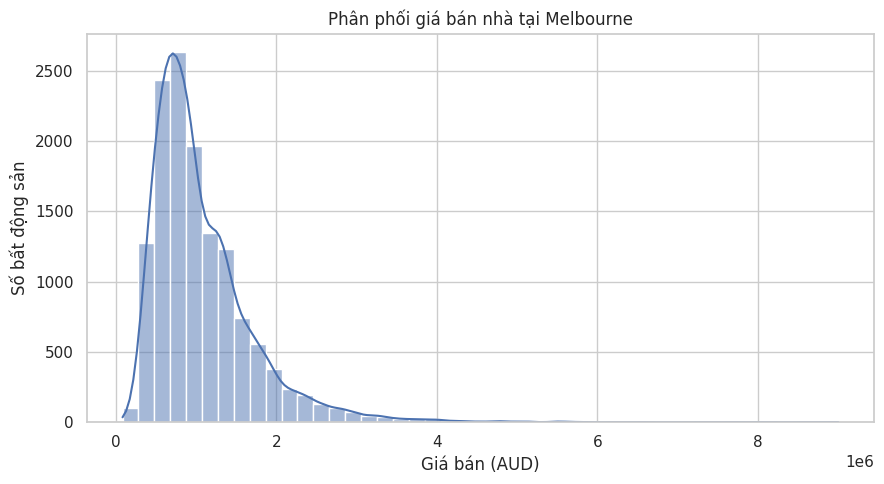

In [169]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_clean["Price"].dropna(), bins=45, kde=True, color=sns.color_palette()[0], ax=ax)
ax.set(title="Phân phối giá bán nhà tại Melbourne", xlabel="Giá bán (AUD)", ylabel="Số bất động sản")
plt.tight_layout()
plt.show()

## 13. Trực quan hóa 2 — So sánh biến động giá theo loại bất động sản (Boxplot)

**Mục tiêu:** Sử dụng biểu đồ hộp (Boxplot) để so sánh trung vị, khoảng tứ phân vị (IQR) và các giá trị ngoại lệ (outliers) giữa 3 loại hình bất động sản: `h` (House), `t` (Townhouse) và `u` (Unit/Apartment).

**Nhận xét biểu đồ:**
* **Loại `h` (House - Nhà riêng/Biệt thự):**
  * Giá trung vị cao nhất (~**1.08 triệu AUD**).
  * Khoảng tứ phân vị IQR rộng nhất, thể hiện sự phân hóa giá rất mạnh giữa các phân khúc nhà riêng.
  * Xuất hiện rất nhiều ngoại lệ (outliers) kéo dài lên mức 4 – 9 triệu AUD.
* **Loại `t` (Townhouse - Nhà liền kề):**
  * Giá trung vị ở mức trung bình (~**846,750 AUD**).
  * Biến động giá vừa phải, ít ngoại lệ cực đoan.
* **Loại `u` (Unit/Apartment - Căn hộ/Chung cư):**
  * Giá trung vị thấp nhất (~**560,000 AUD**).
  * Khung giá tập trung và hẹp nhất, phù hợp với nhóm khách hàng có ngân sách vừa phải hoặc nhà đầu tư cho thuê.

> **Kết luận:** Đồ thị Boxplot xác nhận `Type` là biến phân loại có khả năng phân tách giá cực kỳ hiệu quả, đóng vai trò quan trọng trong việc định giá và phân nhóm thị trường bất động sản.

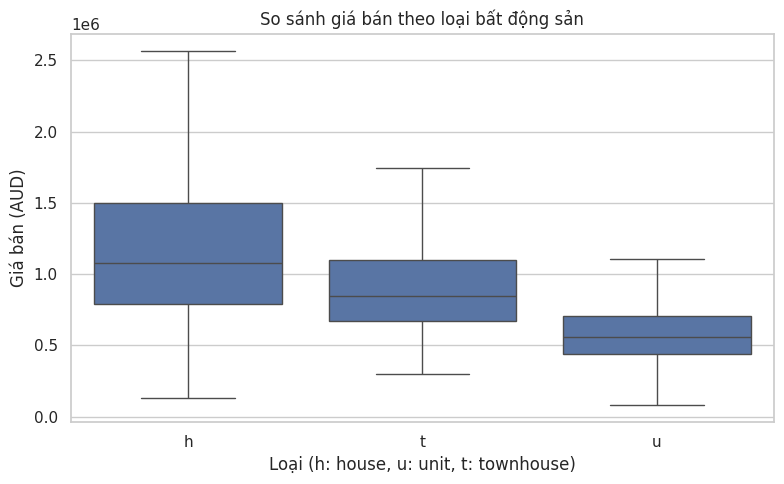

In [170]:
order_type = df_clean.groupby("Type")["Price"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Type", y="Price", order=order_type, showfliers=False, color=sns.color_palette()[0], ax=ax)
ax.set(title="So sánh giá bán theo loại bất động sản", xlabel="Loại (h: house, u: unit, t: townhouse)", ylabel="Giá bán (AUD)")
plt.tight_layout()
plt.show()

## 14. Trực quan hóa 3 — Bar chart giá trung vị theo vùng

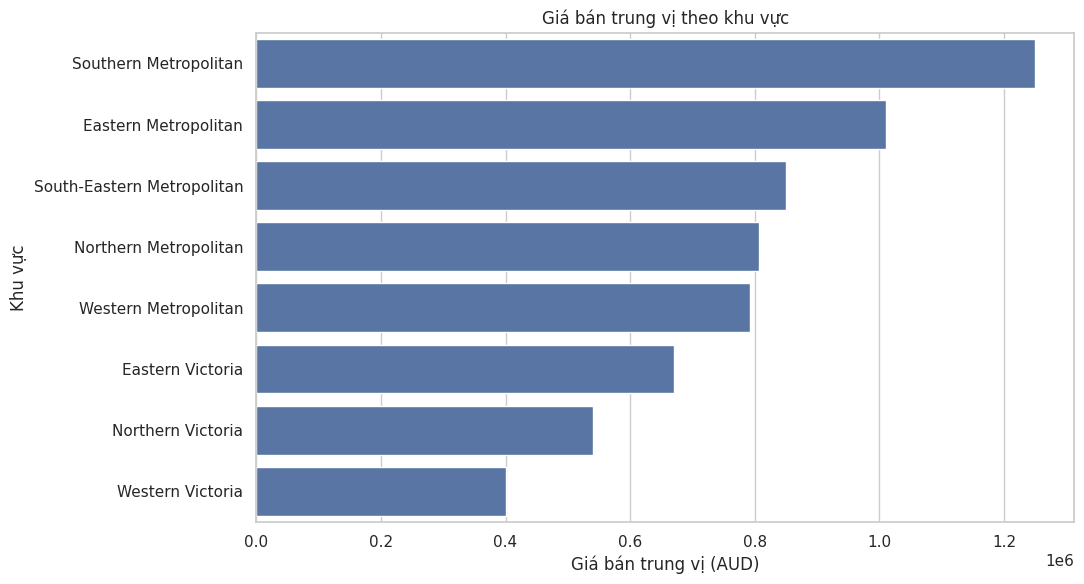

In [171]:
region_median = df_clean.groupby("Regionname")["Price"].median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=region_median.values, y=region_median.index, color=sns.color_palette()[0], ax=ax)
ax.set(title="Giá bán trung vị theo khu vực", xlabel="Giá bán trung vị (AUD)", ylabel="Khu vực")
plt.tight_layout()
plt.show()

## 15. Trực quan hóa 4 — Scatter plot khoảng cách đến CBD và giá

Mẫu tối đa 4.000 điểm được hiển thị để biểu đồ dễ đọc; toàn bộ dữ liệu vẫn được dùng khi tính toán thống kê.

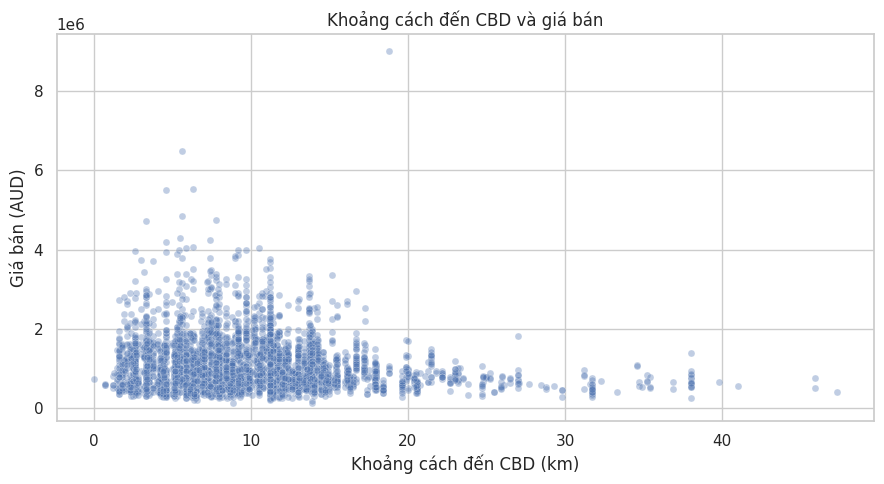

In [172]:
scatter_df = df_clean[["Distance", "Price"]].dropna()
if len(scatter_df) > 4000:
    scatter_df = scatter_df.sample(4000, random_state=42)
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=scatter_df, x="Distance", y="Price", alpha=0.35, s=25, color=sns.color_palette()[0], ax=ax)
ax.set(title="Khoảng cách đến CBD và giá bán", xlabel="Khoảng cách đến CBD (km)", ylabel="Giá bán (AUD)")
plt.tight_layout()
plt.show()

## 16. Trực quan hóa 5 — Heatmap tương quan

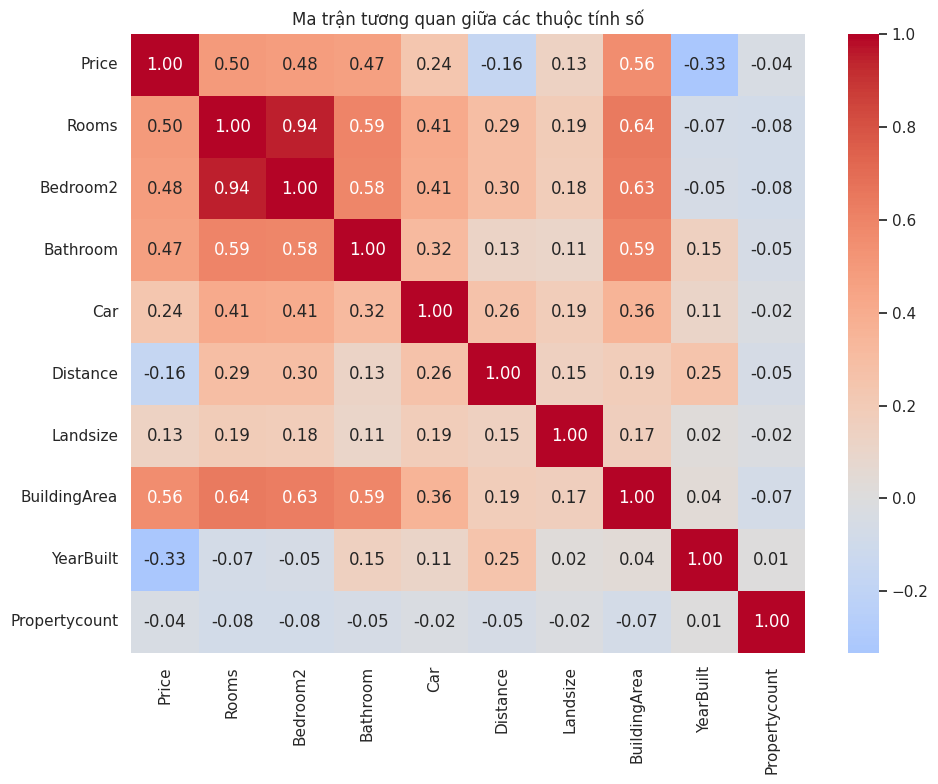

In [173]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Ma trận tương quan giữa các thuộc tính số")
plt.tight_layout()
plt.show()

## 17. Tự động sinh nhận xét từ dữ liệu

Các nhận xét được tính từ `df_clean`.

In [174]:
findings = []

median_by_type = df_clean.groupby("Type")["Price"].median().dropna().sort_values(ascending=False)
if len(median_by_type) >= 2:
    high_type, low_type = median_by_type.index[0], median_by_type.index[-1]
    ratio = median_by_type.iloc[0] / median_by_type.iloc[-1]
    findings.append(
        f"Loại {high_type} có giá trung vị cao nhất ({median_by_type.iloc[0]:,.0f} AUD), "
        f"trong khi loại {low_type} thấp nhất ({median_by_type.iloc[-1]:,.0f} AUD); "
        f"chênh lệch trung vị khoảng {ratio:.2f} lần."
    )

region_stats = df_clean.groupby("Regionname")["Price"].agg(["count", "median"])
region_stats = region_stats[region_stats["count"] >= 30].sort_values("median", ascending=False)
if len(region_stats) >= 2:
    findings.append(
        f"Trong các khu vực có ít nhất 30 bản ghi, {region_stats.index[0]} có giá trung vị cao nhất "
        f"({region_stats.iloc[0]['median']:,.0f} AUD), còn {region_stats.index[-1]} thấp nhất "
        f"({region_stats.iloc[-1]['median']:,.0f} AUD)."
    )

corr_rooms = df_clean["Price"].corr(df_clean["Rooms"])
corr_distance = df_clean["Price"].corr(df_clean["Distance"])
findings.append(
    f"Tương quan Pearson giữa Price và Rooms là {corr_rooms:.2f}; trong snapshot này, hai biến có liên hệ tuyến tính dương, "
    "nhưng điều đó không chứng minh số phòng là nguyên nhân duy nhất làm giá tăng."
)
findings.append(
    f"Tương quan Pearson giữa Price và Distance là {corr_distance:.2f}; liên hệ tuyến tính với khoảng cách đến CBD "
    "yếu hơn liên hệ với số phòng trong tập dữ liệu này."
)

missing_area = df_clean["BuildingArea"].isna().mean() * 100
missing_year = df_clean["YearBuilt"].isna().mean() * 100
findings.append(
    f"BuildingArea còn thiếu {missing_area:.1f}% và YearBuilt còn thiếu {missing_year:.1f}% sau khi làm sạch; "
    "cần cân nhắc cẩn thận trước khi dùng hai cột này trong mô hình hoặc thống kê."
)

for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

with (OUTPUT_DIR / "findings.txt").open("w", encoding="utf-8") as f:
    f.write("\n".join(f"{i}. {finding}" for i, finding in enumerate(findings, start=1)))
print("\nĐã lưu nhận xét vào:", OUTPUT_DIR / "findings.txt")

1. Loại h có giá trung vị cao nhất (1,080,000 AUD), trong khi loại u thấp nhất (560,000 AUD); chênh lệch trung vị khoảng 1.93 lần.
2. Trong các khu vực có ít nhất 30 bản ghi, Southern Metropolitan có giá trung vị cao nhất (1,250,000 AUD), còn Western Victoria thấp nhất (400,000 AUD).
3. Tương quan Pearson giữa Price và Rooms là 0.50; trong snapshot này, hai biến có liên hệ tuyến tính dương, nhưng điều đó không chứng minh số phòng là nguyên nhân duy nhất làm giá tăng.
4. Tương quan Pearson giữa Price và Distance là -0.16; liên hệ tuyến tính với khoảng cách đến CBD yếu hơn liên hệ với số phòng trong tập dữ liệu này.
5. BuildingArea còn thiếu 47.7% và YearBuilt còn thiếu 39.6% sau khi làm sạch; cần cân nhắc cẩn thận trước khi dùng hai cột này trong mô hình hoặc thống kê.

Đã lưu nhận xét vào: /content/outputs/findings.txt


## 18. Kết luận và giới hạn

- Đã đáp ứng quy mô tối thiểu: trên 500 bản ghi và trên 5 thuộc tính.
- Có mô tả nguồn, đọc dữ liệu bằng Pandas, kiểm tra kiểu dữ liệu, dữ liệu thiếu/trùng/không hợp lý và làm sạch có giải thích.
- Có ít nhất 5 phép phân tích dùng `groupby`, lọc, sắp xếp hoặc tổng hợp; có 5 biểu đồ thuộc nhiều loại khác nhau.
- Các nhận xét là mô tả trong snapshot lịch sử của Melbourne giai đoạn 2016–2017. Không suy rộng thành giá thị trường hiện tại.
- `BuildingArea` và `YearBuilt` còn thiếu nhiều dữ liệu. Mô hình Regression trong `train_model.py` điền giá trị thiếu bên trong `Pipeline`, chỉ học từ tập train, để tránh rò rỉ dữ liệu giữa train/validation/test.
- Các giá trị ngoài IQR không tự động xóa. Cần xem ngữ cảnh để quyết định là lỗi nhập liệu hay giao dịch đặc biệt. Các giá trị diện tích phi thực tế (`Landsize` > 10.000 m²: 26 dòng; `BuildingArea` > 1.000 m²: 8 dòng) và 34 dòng `Bathroom == 0` đã được đặt thành thiếu; nhờ vậy Pearson của `BuildingArea` với giá tăng từ 0,09 lên 0,56.

### Có thể phát triển tiếp

1. Phân tích sâu theo thời gian.
2. Cải thiện mô hình Regression trong `train_model.py`: chia tập theo thời gian.

## 19. Training Model

- Đã có data xử lí sạch melb_data_clean.csv nên có thể sử dụng để huấn luyện và xây dựng 1 số model
- Train Model - Chọn Ridge, Random Forest. Gọi thông qua thư viện SKLearn
- 1 số thao tác tiền xử lí trước khi đưa vào model

In [175]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "outputs" / "melb_data_clean.csv"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"
TARGET = "Price"
RANDOM_STATE = 42


Phân loại biến Numeric và biến Categorical

In [176]:
# Biến số
NUMERIC_CANDIDATES = [
    "Rooms", "Bedroom2", "Bathroom", "Car", "Distance",
    "Landsize", "BuildingArea", "YearBuilt", "Lattitude", "Longtitude",
    "Propertycount", "Car_was_missing", "BuildingArea_was_missing",
    "YearBuilt_was_missing", "CouncilArea_was_missing", "SaleYear", "SaleMonth",
]
# Biến phân loại
CATEGORICAL_CANDIDATES = [
    "Suburb", "Type", "Method", "Postcode", "CouncilArea", "Regionname",
]


## 20. Thiết lập Preprocessing Pipeline với Scikit-Learn

**Mục tiêu:** Tự động hóa toàn bộ quy trình biến đổi dữ liệu thô thành dạng số sẵn sàng cho mô hình Machine Learning thông qua `ColumnTransformer` và `Pipeline`.

**Cấu trúc Pipeline tiền xử lý:**
* **Nhóm biến số (Numerical Features):** (`Rooms`, `Distance`, `Bathroom`, `Car`, `Landsize`, `BuildingArea`, `YearBuilt`...)
  * `SimpleImputer(strategy='median')`: Điền các giá trị khuyết thiếu bằng giá trị trung vị của tập Train (tránh ảnh hưởng từ outlier).
  * `StandardScaler()`: Chuẩn hóa dữ liệu về phân phối có $\mu = 0$ và $\sigma = 1$.
* **Nhóm biến phân loại (Categorical Features):** (`Type`, `Method`, `Regionname`...)
  * `SimpleImputer(strategy='most_frequent')`: Điền giá trị khuyết bằng mode.
  * `OneHotEncoder(handle_unknown='ignore', drop='first')`: Biến đổi các giá trị chữ thành chuỗi các biến giả (Dummy variables), loại bỏ cột đầu tiên để tránh hiện tượng đa cộng tuyến.

> **Ưu điểm:** Cấu trúc Pipeline đảm bảo dữ liệu khi đưa vào dự báo thực tế sẽ trải qua chính xác các bước xử lý giống như dữ liệu huấn luyện.

In [177]:
# Hàm tiền xử lý dữ liệu
def build_preprocessor(numeric_features, categorical_features): # 2 tham số truyền
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ],
        remainder="drop",
    )

# Hàm xây dựng mô hình ước lượng với tiền xử lý và biến mục tiêu được biến đổi
def build_estimator(regressor, numeric_features, categorical_features):
    pipeline = Pipeline([
        ("preprocessor", build_preprocessor(numeric_features, categorical_features)),
        ("model", regressor),
    ])

    # Giá nhà lệch phải, train theo log1p(Price) và dự đoán ngược lại bằng expm1.
    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1,
    )

# Hàm đánh giá mô hình qua các chỉ số (MAE, RMSE, R2)
def evaluate(y_true, y_pred):
    return {
        "MAE_AUD": float(mean_absolute_error(y_true, y_pred)),
        "RMSE_AUD": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }


# Một dòng của bảng kiểm tra quá khớp / dưới khớp: sai số trên tập train và trên tập chưa dùng để học.
def build_fit_check_row(model_name, eval_set, train_metrics, eval_metrics):
    return {
        "Model": model_name,
        "Eval_set": eval_set,
        "MAE_train": train_metrics["MAE_AUD"],
        "MAE_eval": eval_metrics["MAE_AUD"],
        "RMSE_train": train_metrics["RMSE_AUD"],
        "RMSE_eval": eval_metrics["RMSE_AUD"],
        "R2_train": train_metrics["R2"],
        "R2_eval": eval_metrics["R2"],
    }


# Gộp các dòng thành bảng và thêm tỷ lệ MAE_eval / MAE_train (gần 1: hai tập tương đương; lớn: có khoảng cách).
def build_fit_check(rows):
    fit_check = pd.DataFrame(rows)
    fit_check["MAE_eval_chia_MAE_train"] = fit_check["MAE_eval"] / fit_check["MAE_train"]
    return fit_check

# Hàm in kết quả fit check
def print_fit_check(fit_check):
    print("\n=== Kiem tra Overfitting / Underfitting (sai so train so voi tap chua dung de hoc) ===")
    print(fit_check.to_string(index=False, formatters={
        "MAE_train": "{:,.0f}".format,
        "MAE_eval": "{:,.0f}".format,
        "RMSE_train": "{:,.0f}".format,
        "RMSE_eval": "{:,.0f}".format,
        "R2_train": "{:.4f}".format,
        "R2_eval": "{:.4f}".format,
        "MAE_eval_chia_MAE_train": "{:.2f}".format,
    }))



1 số hàm tổng hợp các chỉ số (không tác động tới train)

In [178]:
# Hàm tổng hợp số đo sai số mà báo cáo trích (nhóm M); chỉ đọc kết quả đã có, không huấn luyện thêm
def build_model_error_metrics(validation_metrics, metrics, test_results, y_train, y_val, y_test, y_train_full):
    rows = []

    def r(ma, noi_dung, gia_tri, cach_tinh):
        if isinstance(gia_tri, (float, np.floating)):
            gia_tri = round(float(gia_tri), 4)
        rows.append({"ma": ma, "noi_dung": noi_dung, "gia_tri": gia_tri, "cach_tinh": cach_tinh})

    n_total = len(y_train_full) + len(y_test)
    for ten, s in [("train", y_train), ("validation", y_val), ("test", y_test)]:
        r("M06", f"Tập {ten}: số dòng / tỷ lệ / giá trung vị", f"{len(s)} / {len(s) / n_total * 100:.0f}% / {s.median():.0f}", "train_test_split(test_size=0.2, random_state=42) hai lần")
    r("M06", "Train gộp validation (dùng huấn luyện lại)", len(y_train_full), "train_test_split lần 1")

    vm = validation_metrics.set_index("Model")
    tm = metrics.set_index("Model")
    r("M01", "MAE validation của Random Forest thấp hơn Ridge (%)", (1 - vm.loc["RandomForest_log_target", "MAE_AUD"] / vm.loc["Ridge", "MAE_AUD"]) * 100, "outputs/model_validation_metrics.csv")
    r("M01", "MAE test của Random Forest thấp hơn baseline (%)", (1 - tm.loc["RandomForest_log_target", "MAE_AUD"] / tm.loc["Baseline_median", "MAE_AUD"]) * 100, "outputs/model_metrics.csv")
    t = test_results
    a, p = t.ActualPrice, t.PredictedPrice
    e = a - p
    ape = e.abs() / a
    r("M02", "Số dòng test; hệ số tương quan giữa giá thực và giá dự đoán", f"{len(t)}; {np.corrcoef(a, p)[0, 1]:.3f}", "outputs/test_predictions.csv")
    r("M02", "MAPE; sai số tương đối trung vị (%)", f"{ape.mean() * 100:.1f}; {ape.median() * 100:.1f}", "|thực - dự đoán| / thực")
    r("M02", "Tỷ lệ lệch không quá 10%; 20% (%)", f"{(ape <= .1).mean() * 100:.1f}; {(ape <= .2).mean() * 100:.1f}", "|thực - dự đoán| / thực")
    r("M02", "Sai số (thực - dự đoán): trung vị; trung bình", f"{e.median():.0f}; {e.mean():.0f}", "test_results['Residual']")
    hi = a > 1.5e6
    r("M02", "Giá thực trên 1.5 triệu: số dòng; % bị dự đoán thấp", f"{int(hi.sum())}; {(p[hi] < a[hi]).mean() * 100:.0f}", "outputs/test_predictions.csv")
    r("M02", "Giá thực lớn nhất; giá dự đoán lớn nhất", f"{a.max():.0f}; {p.max():.0f}", "outputs/test_predictions.csv")
    seg = pd.cut(a, [0, 6e5, 1e6, 1.5e6, 1e12], right=False, labels=["<600k", "600k-1M", "1M-1.5M", ">=1.5M"])
    for k, gdf in t.assign(seg=seg, ae=e.abs(), ape=ape * 100).groupby("seg", observed=True):
        r("M03", f"Khoảng giá {k}: số dòng; MAE; MAPE (%); lệch trung bình", f"{len(gdf)}; {gdf.ae.mean():.0f}; {gdf.ape.mean():.1f}; {(gdf.ActualPrice - gdf.PredictedPrice).mean():+.0f}", "outputs/test_predictions.csv")
    for k, gdf in t.assign(ae=e.abs(), ape=ape * 100).groupby("Type"):
        r("M03", f"Loại nhà {k}: số dòng; MAE; MAPE (%); lệch trung bình", f"{len(gdf)}; {gdf.ae.mean():.0f}; {gdf.ape.mean():.1f}; {(gdf.ActualPrice - gdf.PredictedPrice).mean():+.0f}", "outputs/test_predictions.csv")
    for k, gdf in t.assign(ae=e.abs()).groupby("Regionname"):
        r("M04", f"Vùng {k}: số dòng test; MAE", f"{len(gdf)}; {gdf.ae.mean():.0f}", "outputs/test_predictions.csv")
    top = t.assign(ae=e.abs(), e=e).sort_values("ae", ascending=False)
    for _, x in top.head(3).iterrows():
        r("M05", "Ba sai số lớn nhất (dự đoán thấp hơn thực tế): suburb, loại, giá thực, giá dự đoán", f"{x.Suburb}, {x.Type}, {x.ActualPrice:.0f}, {x.PredictedPrice:.0f}", "outputs/test_predictions.csv")
    x = top[top.e < 0].iloc[0]
    r("M05", "Sai số lớn nhất theo chiều ngược lại: suburb, loại, giá thực, giá dự đoán", f"{x.Suburb}, {x.Type}, {x.ActualPrice:.0f}, {x.PredictedPrice:.0f}", "outputs/test_predictions.csv")

    return pd.DataFrame(rows)



def save_charts(y_test, best_predictions, best_name):
    # Actual vs predicted chart.
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(y_test, best_predictions, alpha=0.35, s=18)
    lower = min(float(y_test.min()), float(np.min(best_predictions)))
    upper = max(float(y_test.max()), float(np.max(best_predictions)))
    ax.plot([lower, upper], [lower, upper], linestyle="--", color="red")
    ax.set_title(f"Actual vs Predicted — {best_name}")
    ax.set_xlabel("Actual Price (AUD)")
    ax.set_ylabel("Predicted Price (AUD)")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "06_actual_vs_predicted.png", dpi=160)
    plt.close(fig)

    # Residual distribution chart
    residuals = y_test.to_numpy() - best_predictions
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(residuals, bins=40, edgecolor="white")
    ax.axvline(0, linestyle="--", color="red")
    ax.set_title(f"Residual Distribution — {best_name}")
    ax.set_xlabel("Residual (Actual - Predicted), AUD")
    ax.set_ylabel("Number of records")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "07_residual_distribution.png", dpi=160)
    plt.close(fig)


## 21. Chuẩn bị dữ liệu và Phân chia tập Train/Test tiến hành huấn luyện

**Mục tiêu:** Tách tập dữ liệu thành biến độc lập ($X$) và biến phụ thuộc ($y$), đồng thời thực hiện chia tập dữ liệu huấn luyện (`Train Set`) và tập kiểm thử (`Test Set`) để đánh giá khả năng tổng quát hóa của mô hình.

**Các bước xử lý chính:**
1. **Xác định biến phụ thuộc ($y$):** Sử dụng giá trị $\log(\text{Price})$ thay vì `Price` gốc nhằm giảm độ lệch (skewness) của dữ liệu, giúp các mô hình hồi quy hoạt động ổn định và tối ưu hơn.
2. **Xác định tập biến độc lập ($X$):** Loại bỏ các cột định danh/nhiễu (`Address`, `SellerG`, `Date`) và cột mục tiêu `Price`.
3. **Phân chia tỷ lệ 80/20:**
   * **Train Set (80%):** Dùng để huấn luyện mô hình và học các tham số tiền xử lý.
   * **Test Set (20%):** Giữ nguyên làm tập dữ liệu độc lập hoàn toàn (Hold-out) để đánh giá khách quan hiệu năng cuối cùng (`random_state=42`).

**Các thuật toán được thử nghiệm:**
1. **Linear Regression:** Mô hình tuyến tính cơ sở.
2. **Ridge / Lasso Regression:** Mô hình tuyến tính có điều hòa (Regularization $L_1/L_2$) giảm chèn ép nhiễu.
3. **Decision Tree Regressor:** Mô hình cây quyết định phi tuyến.
4. **Random Forest Regressor:** Mô hình học kết hợp (Ensemble - Bagging) giảm Overfitting.

**Thước đo đánh giá (Evaluation Metrics):**
* **$R^2$ Score (Coefficient of Determination):** Tỷ lệ biến thiên của giá nhà được giải thích bởi mô hình (càng gần 1 càng tốt).
* **MAE (Mean Absolute Error):** Độ lệch tuyệt đối trung bình (được quy đổi ngược về đơn vị AUD).
* **RMSE (Root Mean Squared Error):** Căn bậc hai độ lỗi bình phương trung bình, phạt nặng các lỗi dự báo lớn.

In [154]:
def main():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Khong tim thay {DATA_PATH}. Hay chay pipeline.py truoc de tao du lieu da lam sach."
        )

    df = pd.read_csv(DATA_PATH)
    if TARGET not in df.columns:
        raise KeyError(f"Dataset khong co cot muc tieu {TARGET!r}.")

    # Loại bỏ các giá trị không hợp lệ, không impute biến mục tiêu, giữ Price > 0.
    df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
    df = df.loc[df[TARGET].notna() & (df[TARGET] > 0)].copy()

    numeric_features = [c for c in NUMERIC_CANDIDATES if c in df.columns]
    categorical_features = [c for c in CATEGORICAL_CANDIDATES if c in df.columns]
    feature_columns = numeric_features + categorical_features

    if not feature_columns:
        raise ValueError("Khong tim thay cot dau vao phu hop de huan luyen.")

    X = df[feature_columns].copy()
    y = df[TARGET].astype(float).copy()

    # Chia test riêng ngay từ đầu; validation chỉ dùng để chọn mô hình.
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE
    )

    models = {
        "Ridge": Pipeline([
            ("preprocessor", build_preprocessor(numeric_features, categorical_features)),
            ("model", Ridge(alpha=10.0, solver="lsqr")),
        ]),
        "RandomForest_log_target": build_estimator(
            RandomForestRegressor(
                n_estimators=100,
                min_samples_leaf=2,
                max_features=0.9,
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
            numeric_features,
            categorical_features,
        ),
    }

   # Chọn mô hình bằng validation MAE, không chọn theo tập test.
    validation_rows = []
    fit_check_rows = []
    for name, estimator in models.items():
        print(f"Validation {name} ...")
        estimator.fit(X_train, y_train)
        val_prediction = estimator.predict(X_val)
        val_metrics = evaluate(y_val, val_prediction)
        validation_rows.append({"Model": name, **val_metrics})
        train_metrics = evaluate(y_train, estimator.predict(X_train))
        fit_check_rows.append(build_fit_check_row(name, "validation", train_metrics, val_metrics))

    validation_metrics = pd.DataFrame(validation_rows).sort_values("MAE_AUD").reset_index(drop=True)
    best_name = str(validation_metrics.iloc[0]["Model"])

    # Refitting chỉ trên mô hình đã chọn trên toàn bộ tập train thông qua .fit của SKLearn
    # Tập test chỉ dùng để đánh giá cuối cùng, không dùng chọn mô hình.
    best_model = models[best_name]
    print(f"Final fit and test evaluation: {best_name} ...")
    best_model.fit(X_train_full, y_train_full)
    best_predictions = best_model.predict(X_test)
    best_metrics = evaluate(y_test, best_predictions)
    final_train_metrics = evaluate(y_train_full, best_model.predict(X_train_full))
    fit_check_rows.append(build_fit_check_row(
        f"{best_name} (huấn luyện lại trên train gộp validation)", "test", final_train_metrics, best_metrics
    ))

    baseline = DummyRegressor(strategy="median")
    baseline.fit(X_train_full.iloc[:, [0]], y_train_full)
    baseline_pred = baseline.predict(X_test.iloc[:, [0]])

    metrics = pd.DataFrame([
        {"Model": "Baseline_median", **evaluate(y_test, baseline_pred), "Selected_by_validation": False},
        {"Model": best_name, **best_metrics, "Selected_by_validation": True},
    ]).sort_values("MAE_AUD").reset_index(drop=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    validation_metrics.to_csv(
        OUTPUT_DIR / "model_validation_metrics.csv", index=False, encoding="utf-8-sig"
    )

    fit_check = build_fit_check(fit_check_rows)
    fit_check.to_csv(OUTPUT_DIR / "model_fit_check.csv", index=False, encoding="utf-8-sig")

    joblib.dump(best_model, MODEL_DIR / "best_pipeline.joblib")
    metrics.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False, encoding="utf-8-sig")

    test_results = X_test.copy()
    test_results.insert(0, "ActualPrice", y_test.to_numpy())
    test_results["PredictedPrice"] = best_predictions
    test_results["Residual"] = test_results["ActualPrice"] - test_results["PredictedPrice"]
    test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")

    build_model_error_metrics(
        validation_metrics, metrics, test_results, y_train, y_val, y_test, y_train_full
    ).to_csv(OUTPUT_DIR / "model_error_metrics.csv", index=False, encoding="utf-8-sig")

    metadata = {
        "target": TARGET,
        "best_model": best_name,
        "best_metrics": best_metrics,
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "all_features": feature_columns,
        "train_rows": int(len(X_train_full)),
        "validation_rows": int(len(X_val)),
        "test_rows": int(len(X_test)),
        "test_size": 0.2,
        "random_state": RANDOM_STATE,
        "target_transform": "Random Forest trains on log1p(Price) and inverse-transforms predictions; Ridge predicts raw Price; all metrics are in AUD",
        "selection_method": "Lowest validation MAE; final evaluation uses a separate 20% test set",
        "dataset": str(DATA_PATH.relative_to(PROJECT_DIR)),
        "note": "Models were selected on a validation split; a separate test split is used for final evaluation. Use a time-based split for strict future-period forecasting.",
    }
    with (MODEL_DIR / "model_metadata.json").open("w", encoding="utf-8") as f:
        json.dump(metadata, f, ensure_ascii=False, indent=2)

    save_charts(y_test, best_predictions, best_name)

    print("\n=== Model selection (validation set) ===")
    print(validation_metrics.to_string(index=False, formatters={
        "MAE_AUD": "{:,.0f}".format,
        "RMSE_AUD": "{:,.0f}".format,
        "R2": "{:.4f}".format,
    }))
    print("\n=== Final model comparison (test set) ===")
    print(metrics.to_string(index=False, formatters={
        "MAE_AUD": "{:,.0f}".format,
        "RMSE_AUD": "{:,.0f}".format,
        "R2": "{:.4f}".format,
    }))
    print_fit_check(fit_check)
    print(f"\nModel selected by validation MAE: {best_name}")
    print(f"Saved model: {MODEL_DIR / 'best_pipeline.joblib'}")
    print(f"Saved metadata: {MODEL_DIR / 'model_metadata.json'}")
    print(f"Saved predictions and charts in: {OUTPUT_DIR}")
    print("\nFeatures expected by predict():")
    print(feature_columns)


if __name__ == "__main__":
    main()



Validation Ridge ...
Validation RandomForest_log_target ...
Final fit and test evaluation: RandomForest_log_target ...

=== Model selection (validation set) ===
                  Model MAE_AUD RMSE_AUD     R2
RandomForest_log_target 154,819  259,046 0.8150
                  Ridge 231,160  334,104 0.6923

=== Final model comparison (test set) ===
                  Model MAE_AUD RMSE_AUD      R2  Selected_by_validation
RandomForest_log_target 156,536  265,718  0.8222                    True
        Baseline_median 439,350  653,710 -0.0758                   False

=== Kiem tra Overfitting / Underfitting (sai so train so voi tap chua dung de hoc) ===
                                                             Model   Eval_set MAE_train MAE_eval RMSE_train RMSE_eval R2_train R2_eval MAE_eval_chia_MAE_train
                                                             Ridge validation   228,949  231,160    360,806   334,104   0.6927  0.6923                    1.01
                           

Đưa 1 số data vào dự đoán thử

In [155]:
# 1. Đường dẫn đúng tới model đã lưu
PROJECT_DIR = Path.cwd()
model_path = PROJECT_DIR / "models" / "best_pipeline.joblib"
loaded_model = joblib.load(model_path)

# 2. Tạo DataFrame thử nghiệm với đầy đủ các thuộc tính - chỉ có 5 data mẫu
# Pipeline yêu cầu đúng 23 cột đặc trưng như đã định nghĩa khi train
data = {
    "Rooms": [1, 2, 3, 4, 5],
    "Bedroom2": [1, 1, 2, 2, 3],
    "Bathroom": [1, 1, 1, 2, 2],
    "Car": [0, 1, 1, 1, 2],
    "Distance": [10.0, 20.0, 30.0, 40.0, 50.0],
    "Landsize": [100.0, 200.0, 300.0, 400.0, 500.0],
    "BuildingArea": [50.0, 100.0, 150.0, 200.0, 250.0],
    "YearBuilt": [2000, 1990, 1980, 1970, 2010],
    "Lattitude": [-37.8, -37.8, -37.8, -37.8, -37.8],
    "Longtitude": [145.0, 145.0, 145.0, 145.0, 145.0],
    "Propertycount": [4000, 4000, 4000, 4000, 4000],
    "Car_was_missing": [0, 0, 0, 0, 0],
    "BuildingArea_was_missing": [0, 0, 0, 0, 0],
    "YearBuilt_was_missing": [0, 0, 0, 0, 0],
    "CouncilArea_was_missing": [0, 0, 0, 0, 0],
    "SaleYear": [2016, 2016, 2017, 2017, 2017],
    "SaleMonth": [5, 6, 7, 8, 9],
    "Suburb": ["Abbotsford", "Abbotsford", "Albert Park", "Albert Park", "Yarraville"],
    "Type": ["h", "u", "h", "t", "h"],
    "Method": ["S", "S", "S", "SP", "PI"],
    "Postcode": [3067, 3067, 3206, 3206, 3013],
    "CouncilArea": ["Yarra", "Yarra", "Port Phillip", "Port Phillip", "Maribyrnong"],
    "Regionname": ["Northern Metropolitan", "Northern Metropolitan", "Southern Metropolitan", "Southern Metropolitan", "Western Metropolitan"]
}

predict_df = pd.DataFrame(data)

# 3. Dự đoán giá nhà (đầu ra sẽ tự động được expm1 về giá trị gốc nhờ TransformedTargetRegressor)
predictions = loaded_model.predict(predict_df)

# 4. Hiển thị kết quả dự đoán
predict_df["Predicted_Price_AUD"] = predictions
display(predict_df[["Rooms", "Type", "Suburb", "Predicted_Price_AUD"]])

,Rooms,Type,Suburb,Predicted_Price_AUD
0,1,h,Abbotsford,4.985014e+05
1,2,u,Abbotsford,6.048199e+05
2,3,h,Albert Park,1.215952e+06
3,4,t,Albert Park,1.638227e+06
4,5,h,Yarraville,9.436297e+05
